---
# **Pokédex AI**
## **02. Modelo Base**
---


### **1. Entorno y Configuración**


In [ ]:
# Bibliotecas estándar de Python.
import hashlib
import json
import math
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter
from zipfile import ZIP_DEFLATED, ZipFile

# Análisis, visualización y evaluación.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

# Construcción y entrenamiento de la red neuronal.
import tensorflow as tf
from tensorflow.keras import layers

# Acceso a Google Drive.
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Parámetros iniciales del modelo base.
SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
MAX_EPOCHS = 30
LEARNING_RATE = 0.001
EARLY_STOPPING_PATIENCE = 5
DATASET_ZIP = Path("/content/drive/MyDrive/Pokedex/prepared_dataset.zip")

# Para conservar los resultados de la sesión.
WORK_DIR = Path.cwd() / "pokemon_project"
OUTPUT_ROOT = WORK_DIR / "model_runs"
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RUN_DIR = OUTPUT_ROOT / RUN_ID
DATA_DIR = WORK_DIR / "training_data" / RUN_ID
CHECKPOINT_DIR = RUN_DIR / "checkpoints"
EXPORT_DIR = RUN_DIR / "export"

for directory in [DATA_DIR, CHECKPOINT_DIR, EXPORT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# Configuraciónes adicionales de librerías.
tf.keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", 15)
pd.set_option("display.max_colwidth", 65)

In [ ]:
print(f"TensorFlow: {tf.__version__}")
print(f'GPU disponibles: {len(tf.config.list_physical_devices("GPU"))}')
print(f"Resultados de esta ejecución: {RUN_DIR}")
print("ZIP encontrado:", DATASET_ZIP.is_file())

TensorFlow: 2.21.0
GPU disponibles: 1
Resultados de esta ejecución: /content/pokemon_project/model_runs/20261103T020622019114Z
ZIP encontrado: True


### **2. Carga del Dataset Preparado**


In [ ]:
def load_prepared_dataset(zip_path, destination):
    """Extraer el dataset preparado y cargar el manifiesto y las clases."""
    if not zip_path.is_file():
        raise FileNotFoundError(f"No se encontró el dataset: {zip_path}")

    with ZipFile(zip_path) as archive:
        required_files = {"splits.csv", "class_names.json"}
        if not required_files.issubset(archive.namelist()):
            raise ValueError("El ZIP debe incluir splits.csv y class_names.json.")

        # Mantener todos los archivos dentro de la carpeta de extracción.
        extraction_root = destination.resolve()
        for filename in archive.namelist():
            path = (extraction_root / filename).resolve()
            if not path.is_relative_to(extraction_root):
                raise ValueError(f"Ruta de extracción inválida: {filename}")

        archive.extractall(destination)

    manifest = pd.read_csv(destination / "splits.csv")
    class_names = json.loads((destination / "class_names.json").read_text(encoding="utf-8"))

    return manifest, class_names


def organize_splits(manifest, split_order):
    """Organizar las particiones y resumir su distribución."""
    required_columns = {"relative_path", "class_name", "class_index", "split", "group_id"}

    if not required_columns.issubset(manifest.columns):
        raise ValueError("El manifiesto no contiene todas las columnas necesarias.")

    if set(manifest["split"]) != set(split_order):
        raise ValueError("Las particiones deben ser train, val y test.")

    manifest = manifest.copy()
    manifest["class_index"] = manifest["class_index"].astype("int32")

    # Organizar las particiones con un orden fijo de imágenes.
    split_frames = {}
    for split in split_order:
        partition = manifest.loc[manifest["split"] == split]
        partition = partition.sort_values("relative_path").reset_index(drop=True)
        split_frames[split] = partition

    # Resumir las imágenes, clases y grupos de cada partición.
    summary = manifest.groupby("split").agg(
        images=("relative_path", "size"),
        classes=("class_name", "nunique"),
        groups=("group_id", "nunique"),
    )

    summary = summary.reindex(split_order)
    summary["percentage"] = 100 * summary["images"] / len(manifest)

    return split_frames, summary

In [ ]:
# Cargar el dataset y organizar sus particiones.
SPLIT_ORDER = ["train", "val", "test"]

manifest, class_names = load_prepared_dataset(DATASET_ZIP, DATA_DIR)
split_frames, dataset_summary = organize_splits(manifest, SPLIT_ORDER)

NUM_CLASSES = len(class_names)
TOP_K = min(5, NUM_CLASSES)

print(f"Dataset extraído: {DATA_DIR} \n")
display(dataset_summary.round(2))

Dataset extraído: /content/pokemon_project/training_data/20261103T020622019114Z 



,images,classes,groups,percentage
split,,,,
train,4853,150,4853,71.42
val,972,150,971,14.30
test,970,150,970,14.28


### **3. Preparación de los Datos**

In [ ]:
def load_image_tensor(path, label):
    """Leer la imagen preparada sin repetir limpieza, escalado o redimensionamiento."""
    image = tf.io.decode_png(tf.io.read_file(path), channels=3)
    image = tf.ensure_shape(image, [IMAGE_SIZE[0], IMAGE_SIZE[1], 3])
    return image, label


def make_dataset(frame, shuffle=False):
    """Crear lotes siguiendo el manifiesto, mantener orden cuando shuffle=False."""
    paths = [str(DATA_DIR / path) for path in frame["relative_path"]]
    labels = frame["class_index"].to_numpy(dtype=np.int32)
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(load_image_tensor, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        dataset = dataset.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [ ]:
train_ds = make_dataset(split_frames["train"], shuffle=True)
train_eval_ds = make_dataset(split_frames["train"])
val_ds = make_dataset(split_frames["val"])

### **4. Arquitectura del Modelo Base**


In [ ]:
def build_base_model():
    """Construir la CNN base con escalado integrado."""
    model = tf.keras.Sequential(name="pokemon_cnn_base")

    # Entrada y normalización.
    model.add(layers.Input(shape=(*IMAGE_SIZE, 3), name="image"))
    model.add(layers.Rescaling(1 / 255, name="pixel_scaling"))

    # Extracción de características.
    for block, filters in enumerate([32, 64, 128], start=1):
        model.add(layers.Conv2D(
            filters, kernel_size=3, padding="same",
            activation="relu", name=f"conv_{block}",
        ))
        model.add(layers.MaxPooling2D(pool_size=2, name=f"pool_{block}"))

    # Clasificación.
    model.add(layers.GlobalAveragePooling2D(name="global_pooling"))
    model.add(layers.Dense(128, activation="relu", name="classifier"))
    model.add(layers.Dense(NUM_CLASSES, activation="softmax", name="species"))

    return model


def compile_model(model):
    """Configurar el optimizador, la pérdida y las métricas."""
    optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
    loss = tf.keras.losses.SparseCategoricalCrossentropy()
    metrics = [
        tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=TOP_K, name=f"top_{TOP_K}_accuracy",
        ),
    ]

    model.compile(optimizer=optimizer, loss=loss, metrics=metrics)

In [ ]:
model_base = build_base_model()
compile_model(model_base)
model_base.summary()

Model: "pokemon_cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ pixel_scaling (Rescaling)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_pooling                  │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ species (Dense)                 │ (None, 150)            │        19,350 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 129,110 (504.34 KB)

 Trainable params: 129,110 (504.34 KB)

 Non-trainable params: 0 (0.00 B)

### **5. Entrenamiento del Modelo**


In [ ]:
def create_callbacks(checkpoint_path, patience):
    """Guardar la mejor época y detener entrenamientos sin mejora o con pérdida inválida."""
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=patience,
            restore_best_weights=True,
        ),
        tf.keras.callbacks.TerminateOnNaN(),
    ]


def train_model(model, train_dataset, val_dataset, checkpoint_path, epochs, patience):
    """Entrenar el modelo y devolver su historial, duración y mejor época."""
    callbacks = create_callbacks(checkpoint_path, patience)

    # Medir el tiempo del entrenamiento, incluida la validación.
    start = perf_counter()
    history = model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=epochs,
        callbacks=callbacks,
        verbose=2,
    )
    training_seconds = perf_counter() - start

    # Convertir el historial a valores compatibles con la exportación JSON.
    history_values = {
        metric: [float(value) for value in values]
        for metric, values in history.history.items()
    }

    if not checkpoint_path.is_file() or not np.isfinite(
        history_values["val_loss"]
    ).all():
        raise RuntimeError("No se obtuvo un checkpoint válido.")

    best_epoch = int(np.argmin(history_values["val_loss"])) + 1
    return history_values, training_seconds, best_epoch

In [ ]:
# Entrenar el modelo creado y compilado en la sección de arquitectura.
checkpoint_path = CHECKPOINT_DIR / "best_base.keras"

history_values, training_seconds, best_epoch = train_model(
    model=model_base,
    train_dataset=train_ds,
    val_dataset=val_ds,
    checkpoint_path=checkpoint_path,
    epochs=MAX_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE,
)

Epoch 1/30
152/152 - 23s - 150ms/step - accuracy: 0.0140 - loss: 4.9094 - top_5_accuracy: 0.0591 - val_accuracy: 0.0134 - val_loss: 4.7033 - val_top_5_accuracy: 0.0617
Epoch 2/30
152/152 - 14s - 94ms/step - accuracy: 0.0196 - loss: 4.6323 - top_5_accuracy: 0.0923 - val_accuracy: 0.0185 - val_loss: 4.5718 - val_top_5_accuracy: 0.0885
Epoch 3/30
152/152 - 14s - 94ms/step - accuracy: 0.0311 - loss: 4.4733 - top_5_accuracy: 0.1319 - val_accuracy: 0.0432 - val_loss: 4.2747 - val_top_5_accuracy: 0.1975
Epoch 4/30
152/152 - 14s - 93ms/step - accuracy: 0.0573 - loss: 4.1450 - top_5_accuracy: 0.2174 - val_accuracy: 0.0628 - val_loss: 4.0194 - val_top_5_accuracy: 0.2500
Epoch 5/30
152/152 - 14s - 93ms/step - accuracy: 0.0781 - loss: 3.9200 - top_5_accuracy: 0.2780 - val_accuracy: 0.0782 - val_loss: 3.9482 - val_top_5_accuracy: 0.2809
Epoch 6/30
152/152 - 14s - 92ms/step - accuracy: 0.1111 - loss: 3.7124 - top_5_accuracy: 0.3451 - val_accuracy: 0.0998 - val_loss: 3.7036 - val_top_5_accuracy: 0.33

In [ ]:
print(f'Épocas ejecutadas: {len(history_values["loss"])}')
print(f"Mejor época por pérdida de validación: {best_epoch}")
print(f"Tiempo de entrenamiento: {training_seconds / 60:.2f} minutos")

Épocas ejecutadas: 21
Mejor época por pérdida de validación: 16
Tiempo de entrenamiento: 5.30 minutos


In [ ]:
def plot_training_history(history_values, best_epoch):
    """Graficar la pérdida y la exactitud de entrenamiento y validación."""
    epochs = np.arange(1, len(history_values["loss"]) + 1)
    figure, axes = plt.subplots(2, 1, figsize=(7, 8))

    # Mostrar la pérdida en su escala original.
    axes[0].plot(epochs, history_values["loss"], label="Entrenamiento")
    axes[0].plot(epochs, history_values["val_loss"], label="Validación")
    axes[0].set_title("Pérdida durante el entrenamiento")
    axes[0].set_ylabel("Cross Entropy")

    # Convertir la exactitud a porcentaje.
    axes[1].plot(epochs, np.array(history_values["accuracy"]) * 100, label="Entrenamiento")
    axes[1].plot(epochs, np.array(history_values["val_accuracy"]) * 100, label="Validación")

    axes[1].set_title("Accuracy durante el entrenamiento")
    axes[1].set_ylabel("Accuracy (%)")

    for axis in axes:
        axis.axvline(best_epoch, color="gray", linestyle="--", label="Mejor época")
        axis.set_xlabel("Época")
        axis.legend()

    figure.tight_layout()
    plt.show()
    plt.close(figure)

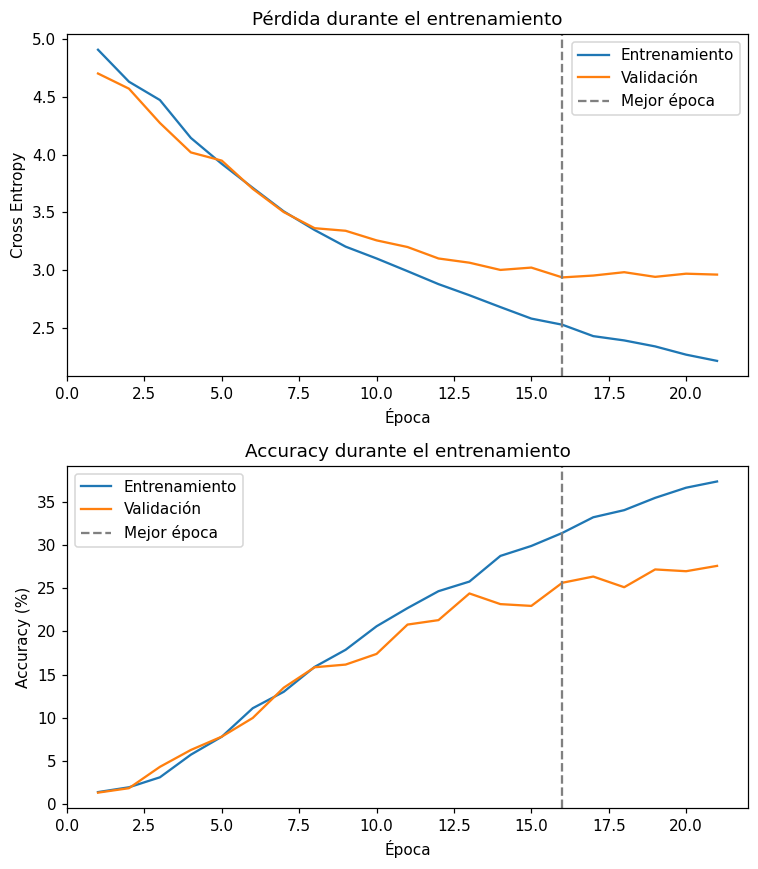

In [ ]:
plot_training_history(history_values, best_epoch)

### **6. Selección del Modelo Base**


In [ ]:
selected_model = tf.keras.models.load_model(checkpoint_path, compile=False)
best_index = best_epoch - 1

selection_summary = pd.DataFrame({
    "model": ["CNN base"],
    "best_epoch": [best_epoch],
    "val_loss": [history_values["val_loss"][best_index]],
    "val_accuracy": [history_values["val_accuracy"][best_index]],
    "parameters": [selected_model.count_params()],
})

display(selection_summary)

,model,best_epoch,val_loss,val_accuracy,parameters
0,CNN base,16,2.936326,0.256173,129110


### **7. Evaluación del Modelo Base**

In [ ]:
def calculate_metrics(labels, probabilities):
    """Evaluar clasificación multiclase con el mismo orden de etiquetas del manifiesto."""
    if probabilities.shape != (len(labels), NUM_CLASSES):
        raise ValueError("Las predicciones no coinciden con las filas o las clases esperadas.")

    if not np.isfinite(probabilities).all():
        raise ValueError("Hay predicciones no finitas.")

    predicted = probabilities.argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predicted,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0,
    )

    top_indices = np.argsort(probabilities, axis=1)[:, -TOP_K:]
    top_k_accuracy = np.any(top_indices == labels[:, None], axis=1).mean()
    losses = tf.keras.losses.sparse_categorical_crossentropy(labels, probabilities)

    return {
        "loss": float(tf.reduce_mean(losses)),
        "accuracy": float(accuracy_score(labels, predicted)),
        f"top_{TOP_K}_accuracy": float(top_k_accuracy),
        "precision_macro": float(precision),
        "recall_macro": float(recall),
        "f1_macro": float(f1),
    }

In [ ]:
test_ds = make_dataset(split_frames["test"])
evaluation_datasets = {"train": train_eval_ds, "val": val_ds, "test": test_ds}
evaluation_metrics = {}
predictions_by_split = {}

for split_name, dataset in evaluation_datasets.items():
    probabilities = selected_model.predict(dataset, verbose=0)
    labels = split_frames[split_name]["class_index"].to_numpy(dtype=np.int32)
    evaluation_metrics[split_name] = calculate_metrics(labels, probabilities)
    predictions_by_split[split_name] = probabilities

metrics_table = pd.DataFrame(evaluation_metrics).T.reindex(SPLIT_ORDER)
metrics_table.index.name = "split"
display(metrics_table.round(4))

,loss,accuracy,top_5_accuracy,precision_macro,recall_macro,f1_macro
split,,,,,,
train,2.3703,0.3519,0.7064,0.3707,0.3407,0.3131
val,2.9363,0.2562,0.5689,0.2435,0.2696,0.2269
test,3.0626,0.2278,0.5515,0.2059,0.2342,0.1883


### **8. Análisis de Errores en Validación**


In [ ]:
def get_class_metrics(labels, predicted, class_names, top_n=10):
    """Calcular las métricas por clase e identificar las de menor F1."""
    report = classification_report(
        labels,
        predicted,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )

    metrics = pd.DataFrame(report).T.loc[class_names].copy()
    metrics.index.name = "class_name"
    metrics["support"] = metrics["support"].astype(int)

    worst_classes = metrics.sort_values(["f1-score", "recall"]).head(top_n)
    return report, metrics, worst_classes

In [ ]:
# Obtener las etiquetas y predicciones de validación.
val_labels = split_frames["val"]["class_index"].to_numpy(dtype=np.int32)
val_probabilities = predictions_by_split["val"]
val_predicted = val_probabilities.argmax(axis=1)

# Calcular y mostrar las clases con menor F1.
validation_report, per_class_metrics, worst_classes = get_class_metrics(
    val_labels, val_predicted, class_names
)
display(worst_classes.round(4))

,precision,recall,f1-score,support
class_name,,,,
Abra,0.0,0.0,0.0,8
Aerodactyl,0.0,0.0,0.0,5
Alolan Sandslash,0.0,0.0,0.0,5
Butterfree,0.0,0.0,0.0,2
Chansey,0.0,0.0,0.0,4
Cubone,0.0,0.0,0.0,8
Dewgong,0.0,0.0,0.0,7
Dodrio,0.0,0.0,0.0,6
Dratini,0.0,0.0,0.0,7


In [ ]:
def plot_class_confusions(matrix, class_names, selected_classes):
    """Mostrar las confusiones de las clases seleccionadas, incluyendo Otras."""
    indices = [class_names.index(name) for name in selected_classes]
    selected_rows = matrix[indices]
    selected_columns = selected_rows[:, indices]

    # Agrupar las predicciones hacia clases fuera del recorte.
    totals = selected_rows.sum(axis=1, keepdims=True)
    others = totals[:, 0] - selected_columns.sum(axis=1)
    counts = np.column_stack([selected_columns, others])
    proportions = np.divide(
        counts, totals,
        out=np.zeros_like(counts, dtype=float),
        where=totals != 0,
    )

    figure, axis = plt.subplots(figsize=(12, 7))
    image = axis.imshow(proportions, cmap="Blues", vmin=0, vmax=1)

    column_names = list(selected_classes) + ["Otras"]
    axis.set_xticks(
        range(len(column_names)), column_names, rotation=55, ha="right"
    )
    axis.set_yticks(range(len(selected_classes)), selected_classes)
    axis.set_xlabel("Clase predicha")
    axis.set_ylabel("Clase real")
    axis.set_title("Validación: confusiones de las clases con menor F1")
    figure.colorbar(image, ax=axis, label="Proporción de imágenes")

    # Anotar únicamente las celdas con observaciones.
    for (row, column), value in np.ndenumerate(proportions):
        if value > 0:
            axis.text(
                column, row, f"{value:.0%}",
                ha="center", va="center",
                color="white" if value > 0.5 else "black",
                fontsize=8,
            )

    figure.tight_layout()
    plt.show()
    plt.close(figure)

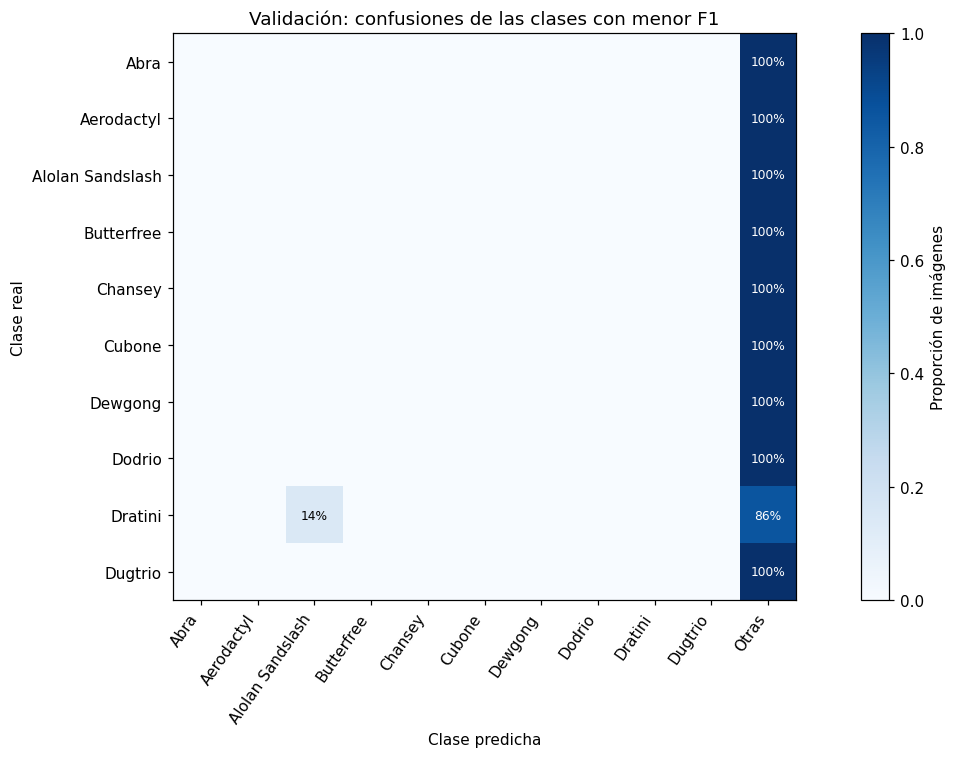

In [ ]:
# Construir la matriz completa y visualizar las clases seleccionadas.
matrix = confusion_matrix(val_labels, val_predicted, labels=np.arange(NUM_CLASSES))
plot_class_confusions(matrix, class_names, worst_classes.index)

In [ ]:
def show_prediction_errors(frame, probabilities, class_names, data_dir, top_n=8):
    """Mostrar errores con las puntuaciones softmax más altas."""
    labels = frame["class_index"].to_numpy(dtype=np.int32)
    predicted = probabilities.argmax(axis=1)
    error_indices = np.flatnonzero(predicted != labels)

    if len(error_indices) == 0:
        print("No se encontraron errores en validación.")
        return

    # Ordenar los errores por la puntuación asignada a la clase predicha.
    scores = probabilities[error_indices].max(axis=1)
    shown_indices = error_indices[np.argsort(-scores)[:top_n]]

    columns = 4
    rows = math.ceil(len(shown_indices) / columns)
    figure, axes = plt.subplots(rows, columns, figsize=(13, 3.5 * rows), squeeze=False)

    for axis in axes.flat:
        axis.axis("off")

    for axis, index in zip(axes.flat, shown_indices):
        image_path = data_dir / frame.iloc[index]["relative_path"]
        with Image.open(image_path) as image:
            axis.imshow(np.asarray(image.convert("RGB")))

        true_name = class_names[labels[index]]
        predicted_name = class_names[predicted[index]]
        score = probabilities[index, predicted[index]]

        axis.set_title(
            f"Real: {true_name}\nPredicha: {predicted_name}\nSoftmax: {score:.3f}",
            fontsize=9,
        )

    figure.tight_layout()
    plt.show()
    plt.close(figure)

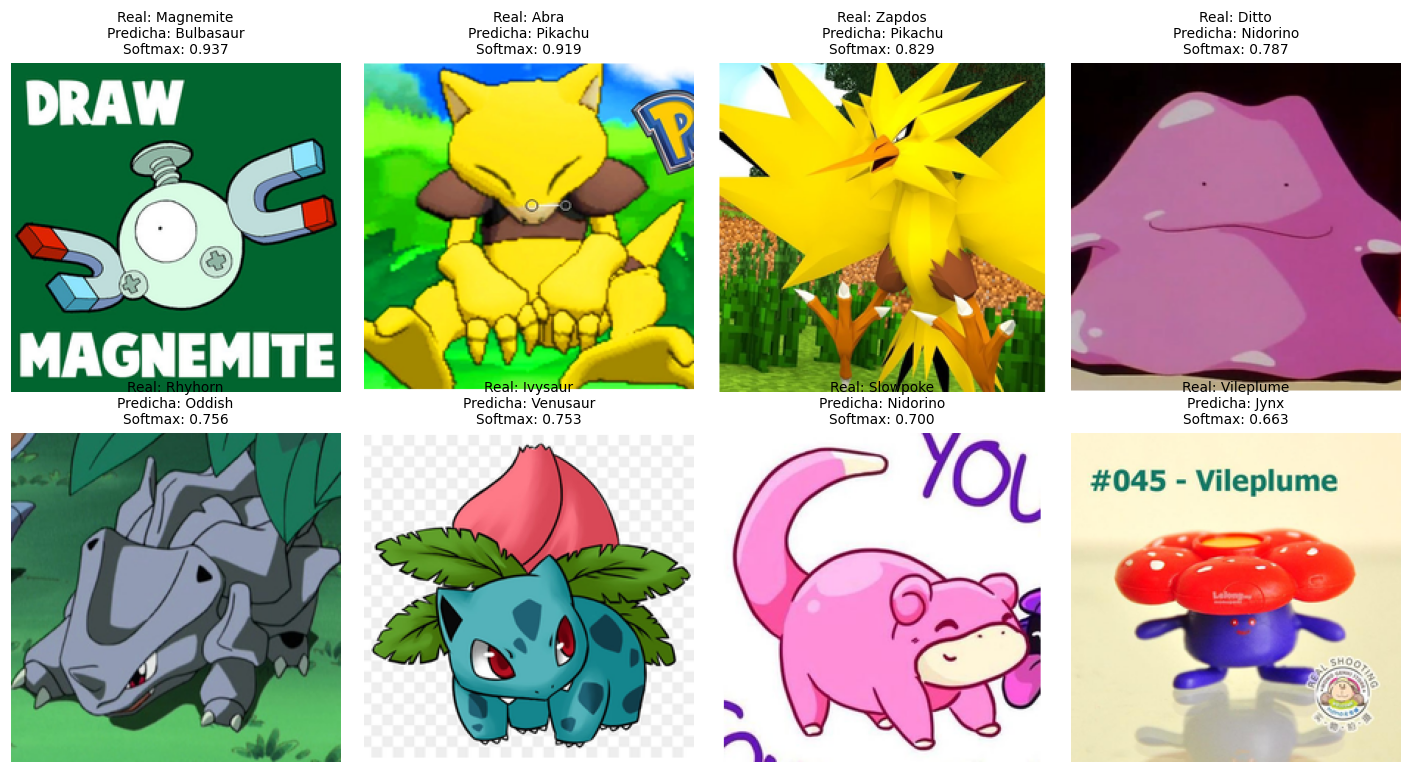

In [ ]:
show_prediction_errors(split_frames["val"], val_probabilities, class_names, DATA_DIR)

### **9. Exportación del Modelo Base**

In [ ]:
def export_model_package(model, class_names, results, export_dir, zip_path):
    """Guardar el modelo, sus resultados y las clases en un paquete ZIP."""
    export_dir.mkdir(parents=True, exist_ok=True)
    zip_path.parent.mkdir(parents=True, exist_ok=True)

    # Guardar la arquitectura y los pesos.
    model_path = export_dir / "base_model.keras"
    model.save(model_path)

    # Guardar los archivos de documentación.
    json_files = {
        "class_names.json": class_names,
        "training_results.json": results,
    }
    for filename, content in json_files.items():
        path = export_dir / filename
        path.write_text(
            json.dumps(content, ensure_ascii=False, indent=2),
            encoding="utf-8",
        )

    # Empaquetar únicamente los tres archivos de exportación.
    export_names = [model_path.name, *json_files]
    with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
        for filename in export_names:
            archive.write(export_dir / filename, arcname=filename)

    with ZipFile(zip_path) as archive:
        if archive.testzip() is not None:
            raise RuntimeError("El ZIP contiene un archivo dañado.")

    return model_path


def verify_saved_model(model, model_path, images):
    """Comprobar que guardar y cargar conserva las predicciones."""
    reloaded_model = tf.keras.models.load_model(model_path, compile=False)

    expected = model(images, training=False).numpy()
    obtained = reloaded_model(images, training=False).numpy()

    np.testing.assert_allclose(expected, obtained, rtol=1e-5, atol=1e-6)

In [ ]:
# Configuración utilizada durante el entrenamiento.
protocol = {
    "seed": SEED,
    "input_shape": [*IMAGE_SIZE, 3],
    "input_range": [0, 255],
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "initial_learning_rate": LEARNING_RATE,
    "maximum_epochs": MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "checkpoint_monitor": "val_loss",
    "augmentation": False,
    "dropout": False,
    "transfer_learning": False,
    "class_count": NUM_CLASSES,
    "tensorflow_version": tf.__version__,
    "split_counts": {
        split: len(frame) for split, frame in split_frames.items()
    },
}

# Identificación, historial y resultados del modelo base.
manifest_path = DATA_DIR / "splits.csv"
manifest_sha256 = hashlib.sha256(manifest_path.read_bytes()).hexdigest()

training_results = {
    "model": "pokemon_cnn_base",
    "status": "baseline_only_improvements_pending",
    "dataset_package": DATASET_ZIP.name,
    "manifest_sha256": manifest_sha256,
    "protocol": protocol,
    "best_epoch": best_epoch,
    "epochs_completed": len(history_values["loss"]),
    "training_seconds": training_seconds,
    "parameters": selected_model.count_params(),
    "history": history_values,
    "metrics": evaluation_metrics,
    "validation_classification_report": validation_report,
    "validation_confusion_matrix": matrix.tolist(),
}

In [ ]:
# Exportar el modelo y los resultados.
model_zip = RUN_DIR / "base_model.zip"

model_path = export_model_package(
    model=selected_model,
    class_names=class_names,
    results=training_results,
    export_dir=EXPORT_DIR,
    zip_path=model_zip,
)

# Verificar las predicciones después de cargar el modelo guardado.
verification_images, _ = next(iter(train_eval_ds))
verify_saved_model(selected_model, model_path, verification_images)

print("Exportación completada y predicciones verificadas.")
print(f"ZIP: {model_zip}")
print(f"Tamaño: {model_zip.stat().st_size / 1024**2:.2f} MiB")

Exportación completada y predicciones verificadas.
ZIP: /content/pokemon_project/model_runs/20261103T020622019114Z/base_model.zip
Tamaño: 0.47 MiB


In [ ]:
DOWNLOAD_MODEL_PACKAGE = True

if DOWNLOAD_MODEL_PACKAGE:
    try:
        from google.colab import files
    except ImportError:
        print(f"Fuera de Colab, copiar el ZIP desde: {model_zip}")
    else:
        files.download(str(model_zip))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>